In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline

# Dataset Loading

In [2]:
flight_df=pd.read_excel("Flight_Fare.xlsx")

In [3]:
flight_df

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302
...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648


# Data Understanding and Initial Quality Checks

In [4]:
flight_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          10683 non-null  str  
 1   Date_of_Journey  10683 non-null  str  
 2   Source           10683 non-null  str  
 3   Destination      10683 non-null  str  
 4   Route            10682 non-null  str  
 5   Dep_Time         10683 non-null  str  
 6   Arrival_Time     10683 non-null  str  
 7   Duration         10683 non-null  str  
 8   Total_Stops      10682 non-null  str  
 9   Additional_Info  10683 non-null  str  
 10  Price            10683 non-null  int64
dtypes: int64(1), str(10)
memory usage: 1.8 MB


In [5]:
flight_df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [6]:
flight_df.shape

(10683, 11)

In [7]:
flight_df.columns

Index(['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
       'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops',
       'Additional_Info', 'Price'],
      dtype='str')

In [8]:
flight_df.dtypes

Airline              str
Date_of_Journey      str
Source               str
Destination          str
Route                str
Dep_Time             str
Arrival_Time         str
Duration             str
Total_Stops          str
Additional_Info      str
Price              int64
dtype: object

In [9]:
flight_df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [10]:
flight_df.duplicated().sum()

np.int64(220)

In [11]:
flight_df["Price"].describe()

count    10683.000000
mean      9087.064121
std       4611.359167
min       1759.000000
25%       5277.000000
50%       8372.000000
75%      12373.000000
max      79512.000000
Name: Price, dtype: float64

In [12]:
# Check records containing missing values

missing_records = flight_df[flight_df.isnull().any(axis=1)]

display(missing_records)

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
9039,Air India,6/05/2019,Delhi,Cochin,NaN,09:45,09:25 07 May,23h 40m,NaN,No info,7480


# Data Cleaning

In [13]:
# Remove records with missing Route or Total_Stops

flight_df = flight_df.dropna(subset=["Route", "Total_Stops"])

flight_df = flight_df.reset_index(drop=True)

print("Dataset Shape:", flight_df.shape)

print("\nMissing Values:")
print(flight_df.isnull().sum())

Dataset Shape: (10682, 11)

Missing Values:
Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64


In [14]:
# Remove duplicate records

flight_df = flight_df.drop_duplicates()

flight_df = flight_df.reset_index(drop=True)

print("Dataset Shape After Removing Duplicates:", flight_df.shape)

Dataset Shape After Removing Duplicates: (10462, 11)


In [15]:
# Check dataset shape
print("Dataset Shape:", flight_df.shape)

# Check missing values
print("\nMissing Values:")
print(flight_df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", flight_df.duplicated().sum())

Dataset Shape: (10462, 11)

Missing Values:
Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64

Duplicate Records: 0


In [16]:
flight_df["Additional_Info"] = flight_df["Additional_Info"].replace({"No Info": "No info"})

In [17]:
print("Dataset Shape:", flight_df.shape)

print("\nMissing Values:")
print(flight_df.isnull().sum())

print("\nDuplicate Records:")
print(flight_df.duplicated().sum())

Dataset Shape: (10462, 11)

Missing Values:
Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64

Duplicate Records:
0


# Exploratory Data Analysis (EDA)

In [18]:
print("Unique Categories:")
print(flight_df["Additional_Info"].unique())

print("\nCategory Counts:")
print(flight_df["Additional_Info"].value_counts())

Unique Categories:
<ArrowStringArray>
[                     'No info',  'In-flight meal not included',
 'No check-in baggage included',              '1 Short layover',
               '1 Long layover',              'Change airports',
               'Business class',               'Red-eye flight',
               '2 Long layover']
Length: 9, dtype: str

Category Counts:
Additional_Info
No info                         8185
In-flight meal not included     1926
No check-in baggage included     318
1 Long layover                    19
Change airports                    7
Business class                     4
1 Short layover                    1
Red-eye flight                     1
2 Long layover                     1
Name: count, dtype: int64


In [19]:
route_counts = flight_df["Route"].value_counts()

print("Total Unique Routes:", flight_df["Route"].nunique())

print("\nTop 15 Most Frequent Routes:")
print(route_counts.head(15))

Total Unique Routes: 128

Top 15 Most Frequent Routes:
Route
DEL → BOM → COK          2376
BLR → DEL                1536
CCU → BOM → BLR           979
CCU → BLR                 724
BOM → HYD                 621
CCU → DEL → BLR           565
BLR → BOM → DEL           402
MAA → CCU                 381
DEL → HYD → COK           326
DEL → BLR → COK           232
DEL → COK                 213
DEL → JAI → BOM → COK     183
DEL → MAA → COK           146
DEL → AMD → BOM → COK     144
DEL → IDR → BOM → COK      90
Name: count, dtype: int64


In [20]:
print("Unique Source Locations:")
print(flight_df["Source"].unique())

print("\nUnique Destination Locations:")
print(flight_df["Destination"].unique())

Unique Source Locations:
<ArrowStringArray>
['Banglore', 'Kolkata', 'Delhi', 'Chennai', 'Mumbai']
Length: 5, dtype: str

Unique Destination Locations:
<ArrowStringArray>
['New Delhi', 'Banglore', 'Cochin', 'Kolkata', 'Delhi', 'Hyderabad']
Length: 6, dtype: str


In [21]:
print("Unique Airlines:")
print(flight_df["Airline"].unique())

print(flight_df["Airline"].value_counts())

Unique Airlines:
<ArrowStringArray>
[                           'IndiGo',                         'Air India',
                       'Jet Airways',                          'SpiceJet',
                 'Multiple carriers',                             'GoAir',
                           'Vistara',                          'Air Asia',
           'Vistara Premium economy',              'Jet Airways Business',
 'Multiple carriers Premium economy',                            'Trujet']
Length: 12, dtype: str
Airline
Jet Airways                          3700
IndiGo                               2043
Air India                            1694
Multiple carriers                    1196
SpiceJet                              815
Vistara                               478
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet               

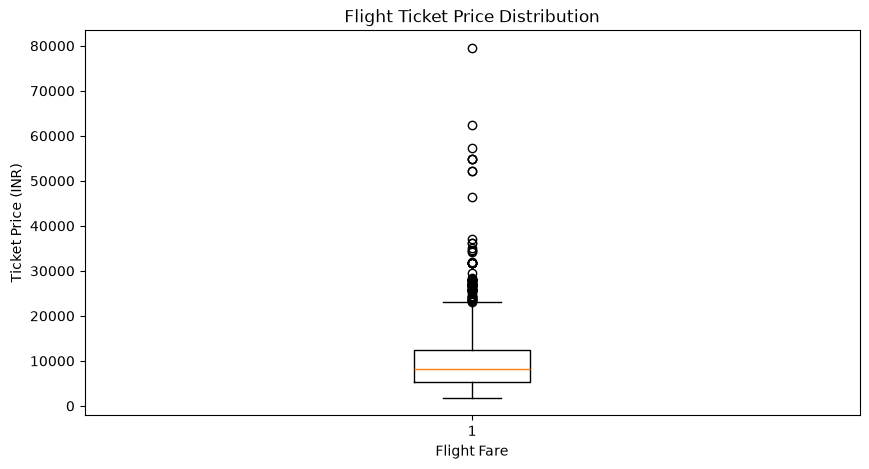

In [22]:
plt.figure(figsize=(10, 5))

plt.boxplot(flight_df["Price"])

plt.title("Flight Ticket Price Distribution")
plt.ylabel("Ticket Price (INR)")
plt.xlabel("Flight Fare")

plt.show()

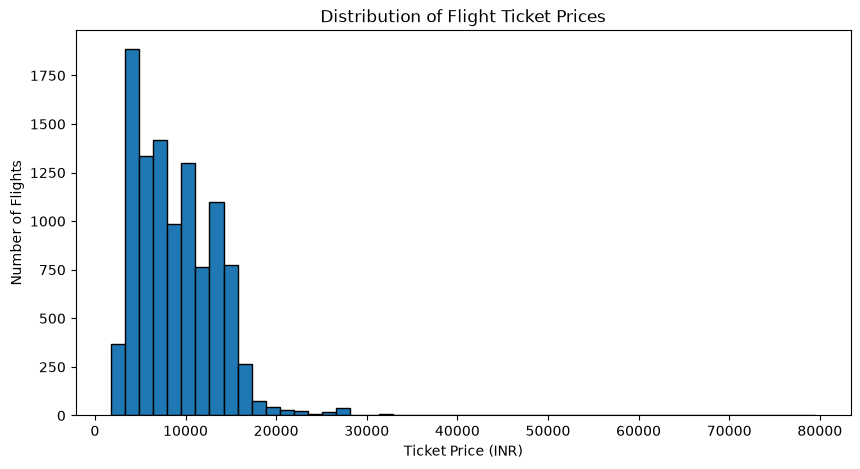

In [23]:
plt.figure(figsize=(10, 5))

plt.hist(flight_df["Price"],bins=50,edgecolor="black")

plt.title("Distribution of Flight Ticket Prices")
plt.xlabel("Ticket Price (INR)")
plt.ylabel("Number of Flights")

plt.show()

In [24]:
for column in flight_df.columns:
   print(f"Unique Values: {flight_df[column].nunique()}")

Unique Values: 12
Unique Values: 44
Unique Values: 5
Unique Values: 6
Unique Values: 128
Unique Values: 222
Unique Values: 1343
Unique Values: 368
Unique Values: 5
Unique Values: 9
Unique Values: 1870


In [25]:
categorical_columns = ["Airline","Source","Destination","Total_Stops","Additional_Info"]

for column in categorical_columns:
   print(flight_df[column].value_counts())

Airline
Jet Airways                          3700
IndiGo                               2043
Air India                            1694
Multiple carriers                    1196
SpiceJet                              815
Vistara                               478
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64
Source
Delhi       4345
Kolkata     2860
Banglore    2179
Mumbai       697
Chennai      381
Name: count, dtype: int64
Destination
Cochin       4345
Banglore     2860
Delhi        1265
New Delhi     914
Hyderabad     697
Kolkata       381
Name: count, dtype: int64
Total_Stops
1 stop      5625
non-stop    3475
2 stops     1318
3 stops       43
4 stops        1
Name: count, dtype: int64
Additional_Info
No info                         8185
In-flight meal not inc

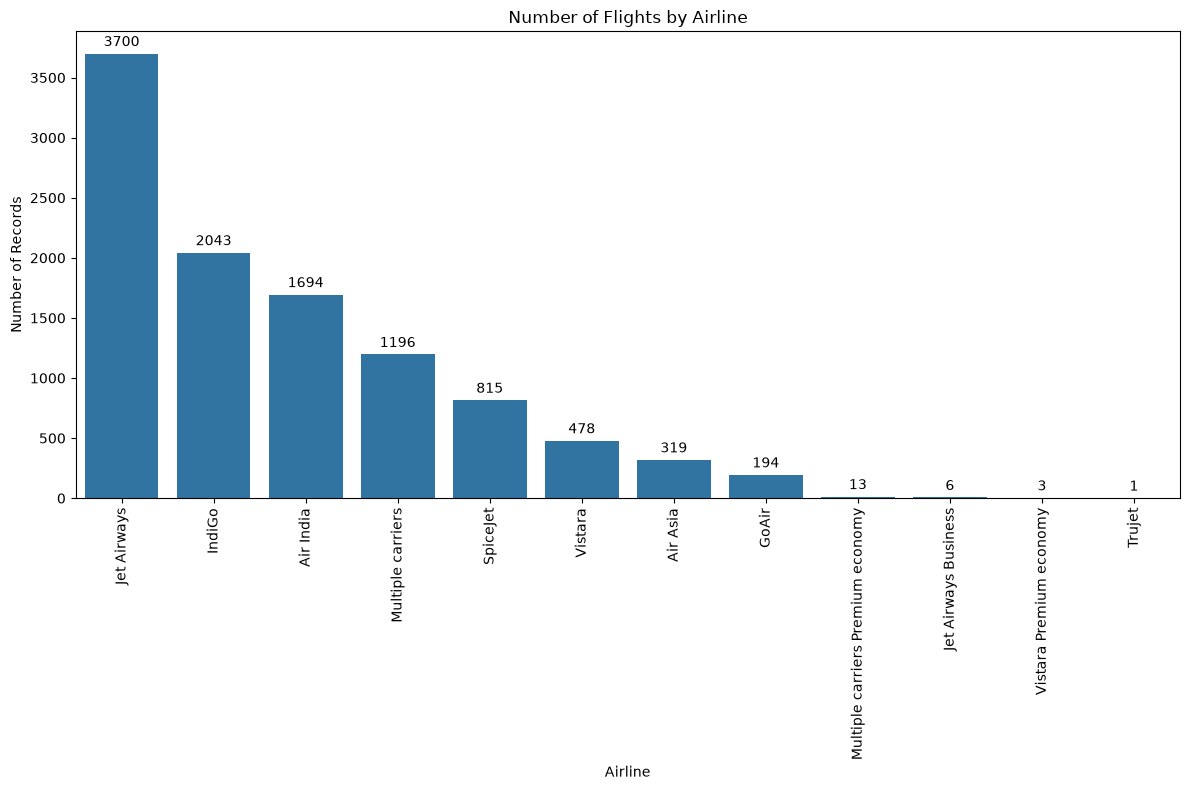

In [26]:
plt.figure(figsize=(12, 8))

ax = sns.countplot(data=flight_df,x="Airline",order=flight_df["Airline"].value_counts().index)

# Display count values above each bar
ax.bar_label(ax.containers[0], padding=3, fmt="%d")

plt.title("Number of Flights by Airline")
plt.xlabel("Airline")
plt.ylabel("Number of Records")
plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

In [27]:
airline_price = (flight_df.groupby("Airline")["Price"].mean().sort_values(ascending=False))

print(airline_price)

Airline
Jet Airways Business                 58358.666667
Jet Airways                          11599.021081
Multiple carriers Premium economy    11418.846154
Multiple carriers                    10902.678094
Air India                             9556.608028
Vistara Premium economy               8962.333333
Vistara                               7801.355649
GoAir                                 5861.056701
IndiGo                                5668.469897
Air Asia                              5590.260188
SpiceJet                              4335.841718
Trujet                                4140.000000
Name: Price, dtype: float64


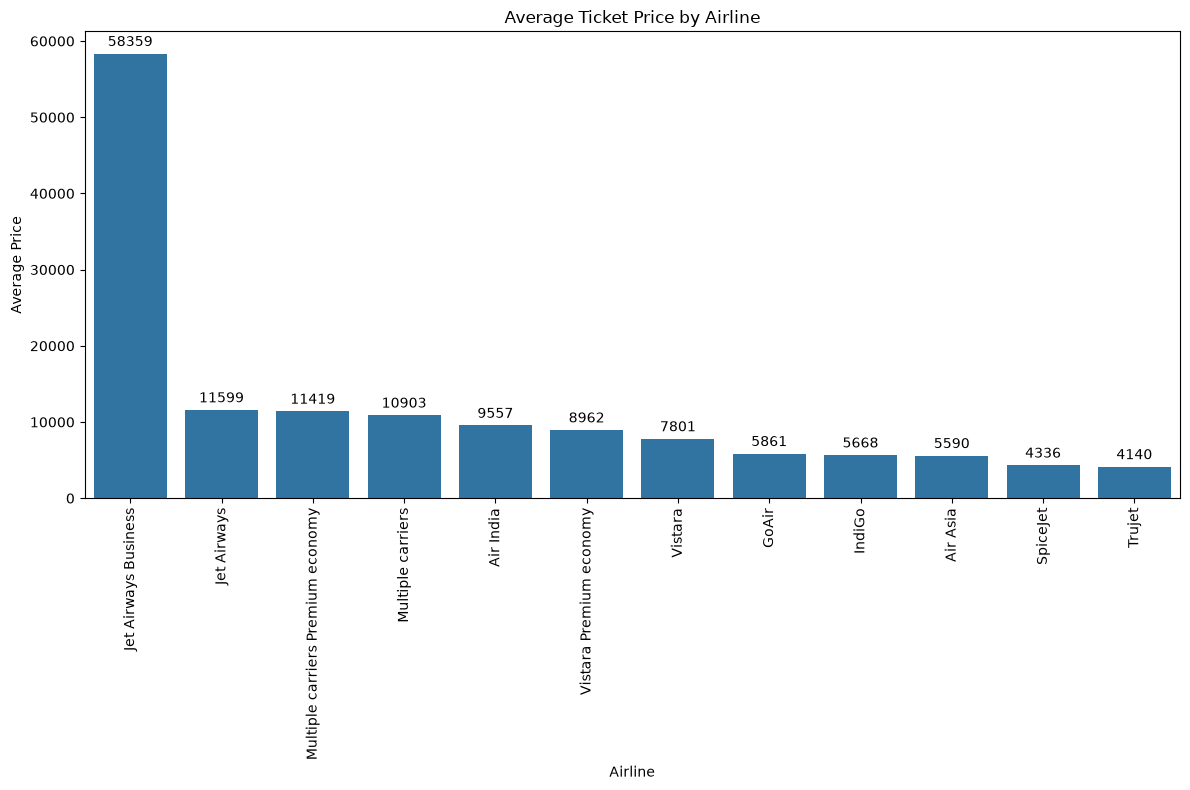

In [28]:
plt.figure(figsize=(12, 8))

ax = sns.barplot(x=airline_price.index,y=airline_price.values)

ax.bar_label(ax.containers[0],fmt="%.0f",padding=3)

plt.title("Average Ticket Price by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Price")
plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

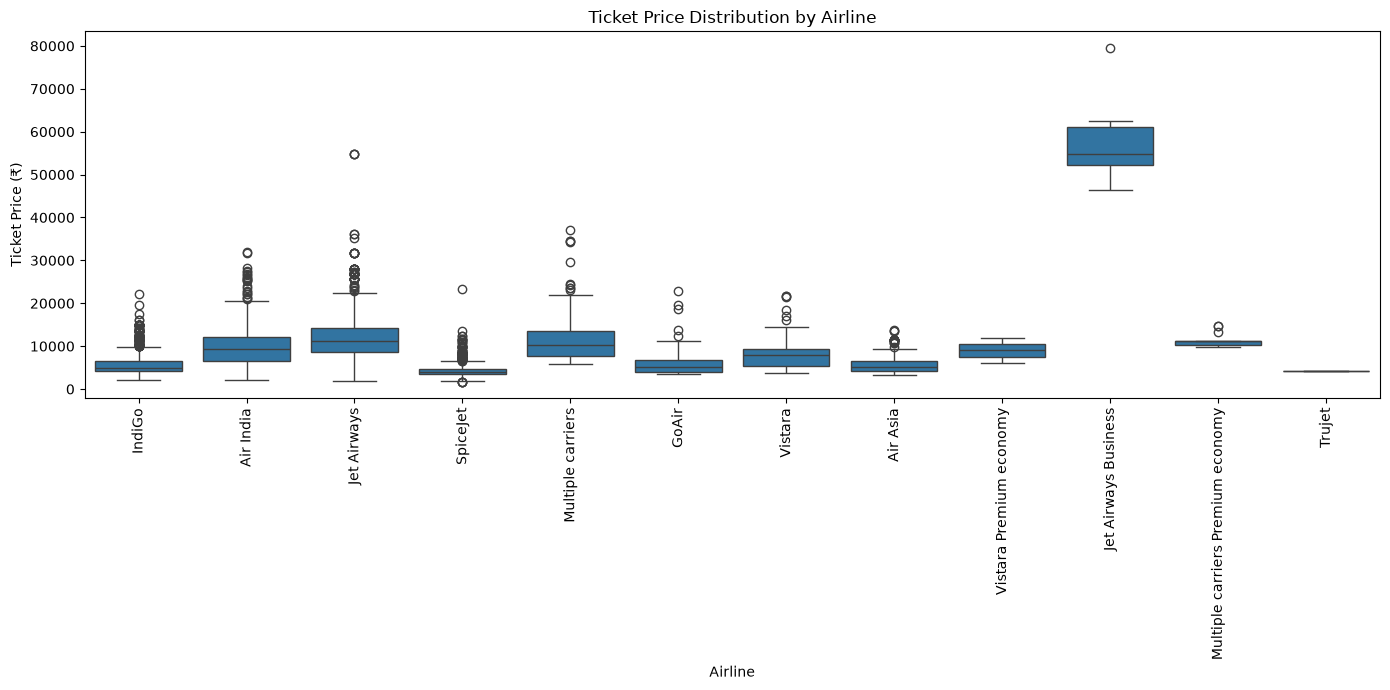

In [29]:
# Relationship Between Airline and Price
plt.figure(figsize=(14, 7))

ax = sns.boxplot(data=flight_df,x="Airline",y="Price")

plt.title("Ticket Price Distribution by Airline")
plt.xlabel("Airline")
plt.ylabel("Ticket Price (₹)")
plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

In [30]:
# Check the ticket price outliers
Q1 = flight_df["Price"].quantile(0.25)
Q3 = flight_df["Price"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - (1.5 * IQR)
upper_limit = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 5224.0
Q3: 12344.75
IQR: 7120.75
Lower Limit: -5457.125
Upper Limit: 23025.875


In [31]:
price_outliers = flight_df[flight_df["Price"] > upper_limit]

print("Number of High-Price Outliers:", len(price_outliers))

display(price_outliers[["Airline","Source","Destination","Route","Total_Stops","Duration","Additional_Info","Price"]]
    .sort_values(by="Price",ascending=False).head(20))

Number of High-Price Outliers: 94


,Airline,Source,Destination,Route,Total_Stops,Duration,Additional_Info,Price
2904,Jet Airways Business,Banglore,New Delhi,BLR → BOM → DEL,1 stop,5h 40m,Business class,79512
5312,Jet Airways Business,Banglore,New Delhi,BLR → BOM → DEL,1 stop,6h 40m,Business class,62427
10159,Jet Airways Business,Banglore,New Delhi,BLR → MAA → DEL,1 stop,4h 40m,Business class,57209
5378,Jet Airways,Banglore,New Delhi,BLR → BOM → DEL,1 stop,6h 5m,No info,54826
2604,Jet Airways,Banglore,New Delhi,BLR → BOM → DEL,1 stop,6h 15m,No info,54826
1474,Jet Airways,Banglore,New Delhi,BLR → BOM → DEL,1 stop,6h 5m,No info,54826
9537,Jet Airways Business,Delhi,Cochin,DEL → ATQ → BOM → COK,2 stops,8h 20m,No info,52285
657,Jet Airways Business,Banglore,New Delhi,BLR → BOM → DEL,1 stop,5h,No info,52229
7254,Jet Airways Business,Delhi,Cochin,DEL → ATQ → BOM → COK,2 stops,8h 20m,No info,46490
396,Multiple carriers,Delhi,Cochin,DEL → BOM → COK,1 stop,6h 25m,No info,36983


In [32]:
outlier_airline_analysis = (price_outliers.groupby("Airline")["Price"].agg(["count", "mean", "min", "max"]).sort_values(by="count", ascending=False))

display(outlier_airline_analysis.round(2))

,count,mean,min,max
Airline,,,,
Jet Airways,62,28966.68,23528,54826
Air India,15,26759.07,23677,31945
Multiple carriers,10,28902.70,23170,36983
Jet Airways Business,6,58358.67,46490,79512
SpiceJet,1,23267.00,23267,23267


# Feature Engineering

In [33]:
# Display journey date values

print(flight_df["Date_of_Journey"].head(10))

# Check the data type

print("\nData Type:")
print(flight_df["Date_of_Journey"].dtype)

0    24/03/2019
1     1/05/2019
2     9/06/2019
3    12/05/2019
4    01/03/2019
5    24/06/2019
6    12/03/2019
7    01/03/2019
8    12/03/2019
9    27/05/2019
Name: Date_of_Journey, dtype: str

Data Type:
str


In [34]:
# Convert Date_of_Journey into datetime format

flight_df["Date_of_Journey"] = pd.to_datetime(flight_df["Date_of_Journey"],format="%d/%m/%Y")

# Check the converted values

print(flight_df["Date_of_Journey"].head(10))

# Check the data type

print("\nData Type:")
print(flight_df["Date_of_Journey"].dtype)

0   2019-03-24
1   2019-05-01
2   2019-06-09
3   2019-05-12
4   2019-03-01
5   2019-06-24
6   2019-03-12
7   2019-03-01
8   2019-03-12
9   2019-05-27
Name: Date_of_Journey, dtype: datetime64[us]

Data Type:
datetime64[us]


In [35]:
# Extract journey day

flight_df["Journey_Day"] = flight_df["Date_of_Journey"].dt.day

# Extract journey month

flight_df["Journey_Month"] = flight_df["Date_of_Journey"].dt.month

# Display the results

display(flight_df[["Date_of_Journey", "Journey_Day", "Journey_Month"]].head(10))

,Date_of_Journey,Journey_Day,Journey_Month
0,2019-03-24,24,3
1,2019-05-01,1,5
2,2019-06-09,9,6
3,2019-05-12,12,5
4,2019-03-01,1,3
5,2019-06-24,24,6
6,2019-03-12,12,3
7,2019-03-01,1,3
8,2019-03-12,12,3
9,2019-05-27,27,5


In [36]:
# Check departure time values

print(flight_df["Dep_Time"].head(10))

# Check data type

print("\nData Type:")
print(flight_df["Dep_Time"].dtype)

0    22:20
1    05:50
2    09:25
3    18:05
4    16:50
5    09:00
6    18:55
7    08:00
8    08:55
9    11:25
Name: Dep_Time, dtype: str

Data Type:
str


In [37]:
# Convert Dep_Time into datetime format

flight_df["Dep_Time"] = pd.to_datetime(flight_df["Dep_Time"],format="%H:%M")

# Check converted values

print(flight_df["Dep_Time"].head(10))

# Check data type

print("\nData Type:")
print(flight_df["Dep_Time"].dtype)

0   1900-01-01 22:20:00
1   1900-01-01 05:50:00
2   1900-01-01 09:25:00
3   1900-01-01 18:05:00
4   1900-01-01 16:50:00
5   1900-01-01 09:00:00
6   1900-01-01 18:55:00
7   1900-01-01 08:00:00
8   1900-01-01 08:55:00
9   1900-01-01 11:25:00
Name: Dep_Time, dtype: datetime64[us]

Data Type:
datetime64[us]


In [38]:
# Extract departure hour

flight_df["Departure_Hour"] = flight_df["Dep_Time"].dt.hour

# Extract departure minute

flight_df["Departure_Minute"] = flight_df["Dep_Time"].dt.minute

# Display results

display(flight_df[["Dep_Time", "Departure_Hour", "Departure_Minute"]].head(10))

,Dep_Time,Departure_Hour,Departure_Minute
0,1900-01-01 22:20:00,22,20
1,1900-01-01 05:50:00,5,50
2,1900-01-01 09:25:00,9,25
3,1900-01-01 18:05:00,18,5
4,1900-01-01 16:50:00,16,50
5,1900-01-01 09:00:00,9,0
6,1900-01-01 18:55:00,18,55
7,1900-01-01 08:00:00,8,0
8,1900-01-01 08:55:00,8,55
9,1900-01-01 11:25:00,11,25


In [39]:
# Check arrival time values

print(flight_df["Arrival_Time"].head(10))

# Check data type

print("\nData Type:")
print(flight_df["Arrival_Time"].dtype)

0    01:10 22 Mar
1           13:15
2    04:25 10 Jun
3           23:30
4           21:35
5           11:25
6    10:25 13 Mar
7    05:05 02 Mar
8    10:25 13 Mar
9           19:15
Name: Arrival_Time, dtype: str

Data Type:
str


In [40]:
# Extract only the time portion from Arrival_Time

flight_df["Arrival_Time_Only"] = flight_df["Arrival_Time"].str[:5]

# Convert the extracted time into datetime format

flight_df["Arrival_Time_Only"] = pd.to_datetime(flight_df["Arrival_Time_Only"],format="%H:%M")

# Display the original and converted values

display(flight_df[["Arrival_Time", "Arrival_Time_Only"]].head(10))

# Check the data type

print("\nData Type:")
print(flight_df["Arrival_Time_Only"].dtype)

,Arrival_Time,Arrival_Time_Only
0,01:10 22 Mar,1900-01-01 01:10:00
1,13:15,1900-01-01 13:15:00
2,04:25 10 Jun,1900-01-01 04:25:00
3,23:30,1900-01-01 23:30:00
4,21:35,1900-01-01 21:35:00
5,11:25,1900-01-01 11:25:00
6,10:25 13 Mar,1900-01-01 10:25:00
7,05:05 02 Mar,1900-01-01 05:05:00
8,10:25 13 Mar,1900-01-01 10:25:00
9,19:15,1900-01-01 19:15:00



Data Type:
datetime64[us]


In [41]:
# Extract arrival hour

flight_df["Arrival_Hour"] = flight_df["Arrival_Time_Only"].dt.hour

# Extract arrival minute

flight_df["Arrival_Minute"] = flight_df["Arrival_Time_Only"].dt.minute

# Display the results

display(flight_df[["Arrival_Time", "Arrival_Hour", "Arrival_Minute"]].head(10))

,Arrival_Time,Arrival_Hour,Arrival_Minute
0,01:10 22 Mar,1,10
1,13:15,13,15
2,04:25 10 Jun,4,25
3,23:30,23,30
4,21:35,21,35
5,11:25,11,25
6,10:25 13 Mar,10,25
7,05:05 02 Mar,5,5
8,10:25 13 Mar,10,25
9,19:15,19,15


In [42]:
# Display duration values

print(flight_df["Duration"].head(10))

# Check data type

print("\nData Type:")
print(flight_df["Duration"].dtype)

0     2h 50m
1     7h 25m
2        19h
3     5h 25m
4     4h 45m
5     2h 25m
6    15h 30m
7     21h 5m
8    25h 30m
9     7h 50m
Name: Duration, dtype: str

Data Type:
str


In [43]:
# Create a function to convert duration into minutes

import re

def convert_duration(duration):
    values = re.findall(r'(\d+)', duration)
    hours, minutes = (list(map(int, values)) + [0, 0])[:2]

    return hours * 60 + minutes

In [44]:
# Test duration conversion

print("2h 50m:", convert_duration("2h 50m"))
print("7h 25m:", convert_duration("7h 25m"))
print("19h:", convert_duration("19h"))
print("21h 5m:", convert_duration("21h 5m"))

2h 50m: 170
7h 25m: 445
19h: 1140
21h 5m: 1265


In [45]:
# Convert all flight durations into minutes

flight_df["Duration_Minutes"] = flight_df["Duration"].apply(convert_duration)

# Display original and converted duration

display(flight_df[["Duration", "Duration_Minutes"]].head(10))

,Duration,Duration_Minutes
0,2h 50m,170
1,7h 25m,445
2,19h,1140
3,5h 25m,325
4,4h 45m,285
5,2h 25m,145
6,15h 30m,930
7,21h 5m,1265
8,25h 30m,1530
9,7h 50m,470


In [46]:
print(flight_df["Duration_Minutes"].describe())

count    10462.000000
mean       629.809788
std        500.672163
min         75.000000
25%        170.000000
50%        505.000000
75%        910.000000
max       2860.000000
Name: Duration_Minutes, dtype: float64


In [47]:
# Check unique values in Total_Stops

print(flight_df["Total_Stops"].unique())

# Count each category

print("\nTotal Stops Distribution:")
print(flight_df["Total_Stops"].value_counts())

<ArrowStringArray>
['non-stop', '2 stops', '1 stop', '3 stops', '4 stops']
Length: 5, dtype: str

Total Stops Distribution:
Total_Stops
1 stop      5625
non-stop    3475
2 stops     1318
3 stops       43
4 stops        1
Name: count, dtype: int64


In [48]:
# Create a mapping dictionary

stops_mapping = {"non-stop": 0,"1 stop": 1,"2 stops": 2,"3 stops": 3,"4 stops": 4}

# Create a new numerical column

flight_df["Total_Stops_Numeric"] = flight_df["Total_Stops"].map(stops_mapping)

# Display original and converted values

display(flight_df[["Total_Stops", "Total_Stops_Numeric"]].head(10))

,Total_Stops,Total_Stops_Numeric
0,non-stop,0
1,2 stops,2
2,2 stops,2
3,1 stop,1
4,1 stop,1
5,non-stop,0
6,1 stop,1
7,1 stop,1
8,1 stop,1
9,1 stop,1


In [49]:
print(flight_df["Total_Stops_Numeric"].value_counts().sort_index())

print("\nMissing Values:")
print(flight_df["Total_Stops_Numeric"].isnull().sum())

Total_Stops_Numeric
0    3475
1    5625
2    1318
3      43
4       1
Name: count, dtype: int64

Missing Values:
0


In [50]:
# Check the first 10 route values

print("Sample Routes:")
print(flight_df["Route"].head(10))

# Count unique routes

print("\nTotal Unique Routes:")
print(flight_df["Route"].nunique())

# Display the 10 most common routes

print("\nTop 10 Most Common Routes:")
print(flight_df["Route"].value_counts().head(10))

Sample Routes:
0                BLR → DEL
1    CCU → IXR → BBI → BLR
2    DEL → LKO → BOM → COK
3          CCU → NAG → BLR
4          BLR → NAG → DEL
5                CCU → BLR
6          BLR → BOM → DEL
7          BLR → BOM → DEL
8          BLR → BOM → DEL
9          DEL → BOM → COK
Name: Route, dtype: str

Total Unique Routes:
128

Top 10 Most Common Routes:
Route
DEL → BOM → COK    2376
BLR → DEL          1536
CCU → BOM → BLR     979
CCU → BLR           724
BOM → HYD           621
CCU → DEL → BLR     565
BLR → BOM → DEL     402
MAA → CCU           381
DEL → HYD → COK     326
DEL → BLR → COK     232
Name: count, dtype: int64


In [51]:
# Extract intermediate stops from Route

flight_df["Route_Stops_Count"] = flight_df["Route"].apply(lambda x: len(x.split("→")) - 2)

# Compare route and stop information

display(flight_df[["Route", "Route_Stops_Count", "Total_Stops_Numeric"]].head(10))

,Route,Route_Stops_Count,Total_Stops_Numeric
0,BLR → DEL,0,0
1,CCU → IXR → BBI → BLR,2,2
2,DEL → LKO → BOM → COK,2,2
3,CCU → NAG → BLR,1,1
4,BLR → NAG → DEL,1,1
5,CCU → BLR,0,0
6,BLR → BOM → DEL,1,1
7,BLR → BOM → DEL,1,1
8,BLR → BOM → DEL,1,1
9,DEL → BOM → COK,1,1


In [52]:
# Compare both stop-count columns

matching_records = (flight_df["Route_Stops_Count"] == flight_df["Total_Stops_Numeric"])

print("Matching Records:", matching_records.sum())

print("Non-Matching Records:", (~matching_records).sum())

Matching Records: 10462
Non-Matching Records: 0


In [53]:
print("DataFrame Shape:", flight_df.shape)

print("\nColumn Names and Data Types:")
print(flight_df.dtypes)

DataFrame Shape: (10462, 21)

Column Names and Data Types:
Airline                           str
Date_of_Journey        datetime64[us]
Source                            str
Destination                       str
Route                             str
Dep_Time               datetime64[us]
Arrival_Time                      str
Duration                          str
Total_Stops                       str
Additional_Info                   str
Price                           int64
Journey_Day                     int32
Journey_Month                   int32
Departure_Hour                  int32
Departure_Minute                int32
Arrival_Time_Only      datetime64[us]
Arrival_Hour                    int32
Arrival_Minute                  int32
Duration_Minutes                int64
Total_Stops_Numeric             int64
Route_Stops_Count               int64
dtype: object


In [54]:
display(flight_df[["Source", "Destination", "Route", "Total_Stops_Numeric"]].head(10))

,Source,Destination,Route,Total_Stops_Numeric
0,Banglore,New Delhi,BLR → DEL,0
1,Kolkata,Banglore,CCU → IXR → BBI → BLR,2
2,Delhi,Cochin,DEL → LKO → BOM → COK,2
3,Kolkata,Banglore,CCU → NAG → BLR,1
4,Banglore,New Delhi,BLR → NAG → DEL,1
5,Kolkata,Banglore,CCU → BLR,0
6,Banglore,New Delhi,BLR → BOM → DEL,1
7,Banglore,New Delhi,BLR → BOM → DEL,1
8,Banglore,New Delhi,BLR → BOM → DEL,1
9,Delhi,Cochin,DEL → BOM → COK,1


In [55]:
numerical_columns = ["Journey_Day","Journey_Month","Departure_Hour","Departure_Minute","Arrival_Hour","Arrival_Minute",
                     "Duration_Minutes","Total_Stops_Numeric","Price"]

display(flight_df[numerical_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
Journey_Day,10462.0,13.463200,8.467493,1.0,6.0,12.0,21.00,27.0
Journey_Month,10462.0,4.701491,1.163802,3.0,3.0,5.0,6.00,6.0
Departure_Hour,10462.0,12.478494,5.727227,0.0,8.0,11.0,18.00,23.0
Departure_Minute,10462.0,24.404989,18.815719,0.0,5.0,25.0,40.00,55.0
Arrival_Hour,10462.0,13.387689,6.855547,0.0,8.0,14.0,19.00,23.0
Arrival_Minute,10462.0,24.719939,16.570450,0.0,10.0,25.0,35.00,55.0
Duration_Minutes,10462.0,629.809788,500.672163,75.0,170.0,505.0,910.00,2860.0
Total_Stops_Numeric,10462.0,0.802332,0.660609,0.0,0.0,1.0,1.00,4.0
Price,10462.0,9026.790289,4624.849541,1759.0,5224.0,8266.0,12344.75,79512.0


In [56]:
long_duration_flights = flight_df[flight_df["Duration_Minutes"] > 1440]

print("Number of Flights Above 24 Hours:",len(long_duration_flights))

display(long_duration_flights[["Airline","Source","Destination","Route","Duration","Duration_Minutes","Total_Stops","Price"]].head(20))

Number of Flights Above 24 Hours: 1030


,Airline,Source,Destination,Route,Duration,Duration_Minutes,Total_Stops,Price
8,Jet Airways,Banglore,New Delhi,BLR → BOM → DEL,25h 30m,1530,1 stop,11087
15,Air India,Delhi,Cochin,DEL → AMD → BOM → COK,26h 35m,1595,2 stops,14011
51,Jet Airways,Kolkata,Banglore,CCU → DEL → BLR,25h 20m,1520,1 stop,12121
59,Vistara,Mumbai,Hyderabad,BOM → DEL → HYD,25h 5m,1505,1 stop,12395
61,Air India,Delhi,Cochin,DEL → MAA → COK,27h 20m,1640,1 stop,5117
71,Jet Airways,Banglore,New Delhi,BLR → BOM → DEL,26h 30m,1590,1 stop,9134
108,Air India,Delhi,Cochin,DEL → JDH → BOM → COK,30h 20m,1820,2 stops,11596
145,Jet Airways,Kolkata,Banglore,CCU → BOM → BLR,27h 35m,1655,1 stop,10844
151,Jet Airways,Delhi,Cochin,DEL → BDQ → BOM → COK,24h 25m,1465,2 stops,9270
158,Jet Airways,Kolkata,Banglore,CCU → BOM → BLR,25h 45m,1545,1 stop,10844


In [57]:
longest_flights = flight_df.sort_values(by="Duration_Minutes",ascending=False)

display(longest_flights[["Airline","Source","Destination","Route","Duration","Duration_Minutes","Total_Stops","Price"]].head(20))

,Airline,Source,Destination,Route,Duration,Duration_Minutes,Total_Stops,Price
10247,Jet Airways,Delhi,Cochin,DEL → AMD → BOM → COK,47h 40m,2860,2 stops,20694
1065,Jet Airways,Delhi,Cochin,DEL → IDR → BOM → COK,47h,2820,2 stops,20064
8285,Jet Airways,Delhi,Cochin,DEL → JAI → BOM → COK,42h 45m,2565,2 stops,12819
5884,Jet Airways,Delhi,Cochin,DEL → IDR → BOM → COK,42h 5m,2525,2 stops,11664
7799,Air India,Kolkata,Banglore,CCU → GAU → DEL → BLR,41h 20m,2480,2 stops,13990
10121,Air India,Banglore,New Delhi,BLR → CCU → GAU → DEL,40h 20m,2420,2 stops,11791
6247,Air India,Banglore,New Delhi,BLR → BOM → AMD → DEL,39h 5m,2345,2 stops,17135
5988,Jet Airways,Delhi,Cochin,DEL → MAA → BOM → COK,38h 35m,2315,2 stops,8098
7511,Air India,Banglore,New Delhi,BLR → BOM → BHO → DEL,38h 35m,2315,2 stops,10783
5636,Air India,Banglore,New Delhi,BLR → BOM → BHO → DEL,38h 35m,2315,2 stops,25430


In [58]:
duration_by_stops = (flight_df.groupby("Total_Stops_Numeric")["Duration_Minutes"].agg(["count", "mean", "min", "max"]))

duration_by_stops["mean"] = (duration_by_stops["mean"] / 60)

duration_by_stops["max"] = (duration_by_stops["max"] / 60)

duration_by_stops["min"] = (duration_by_stops["min"] / 60)

display(duration_by_stops.round(2))

,count,mean,min,max
Total_Stops_Numeric,,,,
0,3475,2.50,1.25,3.83
1,5625,13.03,3.25,29.17
2,1318,20.27,2.50,47.67
3,43,25.22,9.42,38.00
4,1,29.50,29.50,29.50


In [59]:
stop_price_analysis = (flight_df.groupby("Total_Stops_Numeric")["Price"].agg(["count", "mean", "median"]))

display(stop_price_analysis.round(2))

,count,mean,median
Total_Stops_Numeric,,,
0,3475,5018.51,4667.0
1,5625,10594.12,10262.0
2,1318,12761.10,12723.0
3,43,13260.67,13007.0
4,1,17686.00,17686.0


In [60]:
matching_records = (flight_df["Route_Stops_Count"] == flight_df["Total_Stops_Numeric"])

print("Matching Records:", matching_records.sum())
print("Non-Matching Records:", (~matching_records).sum())

Matching Records: 10462
Non-Matching Records: 0


In [61]:
flight_df.drop(columns=["Route_Stops_Count"], inplace=True)

C:\Users\Hp\AppData\Local\Temp\ipykernel_25348\2769438043.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  flight_df.drop(columns=["Route_Stops_Count"], inplace=True)


In [62]:
flight_df.columns

Index(['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
       'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops',
       'Additional_Info', 'Price', 'Journey_Day', 'Journey_Month',
       'Departure_Hour', 'Departure_Minute', 'Arrival_Time_Only',
       'Arrival_Hour', 'Arrival_Minute', 'Duration_Minutes',
       'Total_Stops_Numeric'],
      dtype='str')

In [63]:
flight_df[["Journey_Day","Journey_Month","Departure_Hour","Departure_Minute","Arrival_Hour","Arrival_Minute",
           "Duration_Minutes","Total_Stops_Numeric"]].head()

,Journey_Day,Journey_Month,Departure_Hour,Departure_Minute,Arrival_Hour,Arrival_Minute,Duration_Minutes,Total_Stops_Numeric
0,24,3,22,20,1,10,170,0
1,1,5,5,50,13,15,445,2
2,9,6,9,25,4,25,1140,2
3,12,5,18,5,23,30,325,1
4,1,3,16,50,21,35,285,1


In [64]:
engineered_features = ["Journey_Day","Journey_Month","Departure_Hour","Departure_Minute","Arrival_Hour","Arrival_Minute",
                       "Duration_Minutes","Total_Stops_Numeric"]

flight_df[engineered_features].isnull().sum()

Journey_Day            0
Journey_Month          0
Departure_Hour         0
Departure_Minute       0
Arrival_Hour           0
Arrival_Minute         0
Duration_Minutes       0
Total_Stops_Numeric    0
dtype: int64

## Review and Remove the Invalid Duration Record

In [65]:
suspicious_flights = flight_df[(flight_df["Total_Stops_Numeric"] == 2) & (flight_df["Duration_Minutes"] < 60)]

print("Number of Suspicious Flights:", len(suspicious_flights))

display(suspicious_flights[["Airline","Source","Destination","Route","Duration","Duration_Minutes","Total_Stops","Price"]])

Number of Suspicious Flights: 0


,Airline,Source,Destination,Route,Duration,Duration_Minutes,Total_Stops,Price


In [66]:
# Identify the specific invalid record using its values
invalid_flight_mask = ((flight_df["Airline"] == "Air India") & (flight_df["Source"] == "Mumbai") & (flight_df["Destination"] == "Hyderabad") &
    (flight_df["Duration"] == "5m") & (flight_df["Total_Stops"] == "2 stops"))

print("Invalid records identified:", invalid_flight_mask.sum())

# Remove the invalid record and reset the index
flight_df = flight_df.loc[~invalid_flight_mask].copy()
flight_df.reset_index(drop=True, inplace=True)

print("Updated dataset shape:", flight_df.shape)
print("Remaining five-minute records:", (flight_df["Duration"] == "5m").sum())

Invalid records identified: 1
Updated dataset shape: (10461, 20)
Remaining five-minute records: 0


C:\Users\Hp\AppData\Local\Temp\ipykernel_25348\1040111475.py:9: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  flight_df.reset_index(drop=True, inplace=True)


In [67]:
print("Flights Below 1 Hour:",(flight_df["Duration_Minutes"] < 60).sum())

print("Minimum Duration:",flight_df["Duration_Minutes"].min(),"minutes")

Flights Below 1 Hour: 0
Minimum Duration: 75 minutes


In [68]:
# Final data quality verification
print("Final Dataset Shape:", flight_df.shape)
print("Total Missing Values:", flight_df.isnull().sum().sum())
print("Duplicate Records:", flight_df.duplicated().sum())

Final Dataset Shape: (10461, 20)
Total Missing Values: 0
Duplicate Records: 0


# Feature Selection

In [69]:
flight_df.columns.tolist()

['Airline',
 'Date_of_Journey',
 'Source',
 'Destination',
 'Route',
 'Dep_Time',
 'Arrival_Time',
 'Duration',
 'Total_Stops',
 'Additional_Info',
 'Price',
 'Journey_Day',
 'Journey_Month',
 'Departure_Hour',
 'Departure_Minute',
 'Arrival_Time_Only',
 'Arrival_Hour',
 'Arrival_Minute',
 'Duration_Minutes',
 'Total_Stops_Numeric']

In [70]:
categorical_cols = ["Airline","Source","Destination","Route","Additional_Info","Total_Stops"]

for col in categorical_cols:
    print(f"{col}: {flight_df[col].nunique()} unique values")

Airline: 12 unique values
Source: 5 unique values
Destination: 6 unique values
Route: 128 unique values
Additional_Info: 9 unique values
Total_Stops: 5 unique values


In [71]:
flight_df["Additional_Info"].value_counts()

Additional_Info
No info                         8184
In-flight meal not included     1926
No check-in baggage included     318
1 Long layover                    19
Change airports                    7
Business class                     4
1 Short layover                    1
Red-eye flight                     1
2 Long layover                     1
Name: count, dtype: int64

In [72]:
additional_info_price = (flight_df.groupby("Additional_Info")["Price"].agg(["count", "mean", "median"]).sort_values(by="mean", ascending=False))

additional_info_price

,count,mean,median
Additional_Info,,,
Business class,4,56811.250000,59818.0
1 Short layover,1,26743.000000,26743.0
2 Long layover,1,26480.000000,26480.0
1 Long layover,19,22109.631579,25735.0
Change airports,7,16800.714286,15119.0
Red-eye flight,1,10873.000000,10873.0
In-flight meal not included,1926,9435.647456,10262.0
No info,8184,9073.871334,7893.0
No check-in baggage included,318,3642.465409,3841.0


In [73]:
route_counts = flight_df["Route"].value_counts()

print("Total Unique Routes:", flight_df["Route"].nunique())

print("\nTop 15 Most Frequent Routes:")
route_counts.head(15)

Total Unique Routes: 128

Top 15 Most Frequent Routes:


Route
DEL → BOM → COK          2376
BLR → DEL                1536
CCU → BOM → BLR           979
CCU → BLR                 724
BOM → HYD                 621
CCU → DEL → BLR           565
BLR → BOM → DEL           402
MAA → CCU                 381
DEL → HYD → COK           326
DEL → BLR → COK           232
DEL → COK                 213
DEL → JAI → BOM → COK     183
DEL → MAA → COK           146
DEL → AMD → BOM → COK     144
DEL → IDR → BOM → COK      90
Name: count, dtype: int64

In [74]:
route_analysis = (flight_df.groupby("Route")["Price"].agg(["count", "mean", "median"]).sort_values(by="count", ascending=False))

route_analysis.head(15)

,count,mean,median
Route,,,
DEL → BOM → COK,2376,10954.205808,10262.0
BLR → DEL,1536,5552.235677,4823.0
CCU → BOM → BLR,979,11487.788560,10844.0
CCU → BLR,724,4556.055249,4409.0
BOM → HYD,621,3932.809984,3175.0
CCU → DEL → BLR,565,10763.258407,10539.0
BLR → BOM → DEL,402,15723.174129,13555.0
MAA → CCU,381,4789.892388,3850.0
DEL → HYD → COK,326,7299.331288,6689.0


In [75]:
stops_price_analysis = (flight_df.groupby("Total_Stops_Numeric")["Price"].agg(["count", "mean", "median"]).sort_index())

stops_price_analysis

,count,mean,median
Total_Stops_Numeric,,,
0,3475,5018.506763,4667.0
1,5625,10594.123556,10262.0
2,1317,12757.632498,12723.0
3,43,13260.674419,13007.0
4,1,17686.000000,17686.0


In [76]:
flight_df[["Duration_Minutes", "Price"]].corr()

,Duration_Minutes,Price
Duration_Minutes,1.000000,0.502087
Price,0.502087,1.000000


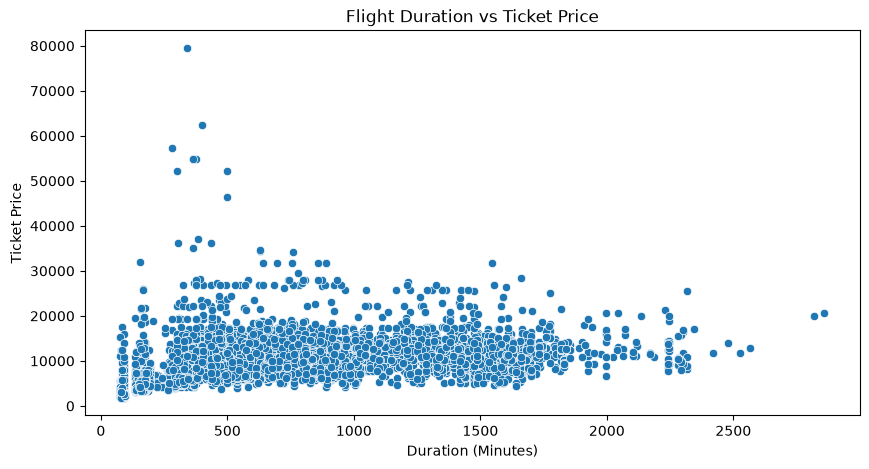

In [77]:
plt.figure(figsize=(10, 5))

sns.scatterplot(data=flight_df,x="Duration_Minutes",y="Price")

plt.title("Flight Duration vs Ticket Price")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Ticket Price")

plt.show()

Feature Selection – Initial Analysis

The initial feature-selection process was performed to identify variables that may influence flight ticket prices.

The following observations were made:

Airline: Retained because different airlines may have different pricing structures.

Source and Destination: Retained because departure and arrival locations may influence ticket prices.

Route: Retained for evaluation because different routes show variations in average ticket prices.

Additional_Info: Retained for evaluation because certain categories show differences in ticket prices.

Total_Stops_Numeric: Retained because the number of stops shows a relationship with ticket prices.

Duration_Minutes: Retained because it has a moderate positive correlation with ticket prices (0.502087).

Journey_Day and Journey_Month: Retained to represent journey date information.

Departure_Hour, Departure_Minute, Arrival_Hour and Arrival_Minute: Retained to represent flight timing information.

Note: These are initial feature-selection decisions. Final feature selection will be refined during model development and evaluation.

# Data Preprocessing and Feature Definition

In [78]:
categorical_features = ["Airline","Source","Destination","Route","Additional_Info"]

In [79]:
numerical_features = ["Journey_Day","Journey_Month","Departure_Hour","Departure_Minute","Arrival_Hour","Arrival_Minute",
                      "Duration_Minutes","Total_Stops_Numeric"]

In [80]:
X = flight_df[categorical_features + numerical_features].copy()

y = flight_df["Price"].copy()

In [81]:
print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

Input Features Shape: (10461, 13)
Target Variable Shape: (10461,)

Input Features:
['Airline', 'Source', 'Destination', 'Route', 'Additional_Info', 'Journey_Day', 'Journey_Month', 'Departure_Hour', 'Departure_Minute', 'Arrival_Hour', 'Arrival_Minute', 'Duration_Minutes', 'Total_Stops_Numeric']

Target Variable:
Price


# Train-Test Split

In [82]:
print("Original Dataset Shape:", flight_df.shape)
print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nMissing Values in Dataset:", flight_df.isnull().sum().sum())
print("Duplicate Records:", flight_df.duplicated().sum())

Original Dataset Shape: (10461, 20)
Input Features Shape: (10461, 13)
Target Variable Shape: (10461,)

Missing Values in Dataset: 0
Duplicate Records: 0


In [83]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [84]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8368, 13)
X_test: (2093, 13)
y_train: (8368,)
y_test: (2093,)


In [85]:
print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)

Categorical Features: ['Airline', 'Source', 'Destination', 'Route', 'Additional_Info']
Numerical Features: ['Journey_Day', 'Journey_Month', 'Departure_Hour', 'Departure_Minute', 'Arrival_Hour', 'Arrival_Minute', 'Duration_Minutes', 'Total_Stops_Numeric']


## Preprocessing Pipeline

In [86]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", StandardScaler(), numerical_features)
    ]
)

In [87]:
# Fit on training data; transform both training and testing data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [88]:
print("Original Training Shape:", X_train.shape)
print("Processed Training Shape:", X_train_processed.shape)

print("\nOriginal Testing Shape:", X_test.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Original Training Shape: (8368, 13)
Processed Training Shape: (8368, 166)

Original Testing Shape: (2093, 13)
Processed Testing Shape: (2093, 166)


In [89]:
encoded_feature_names = preprocessor.get_feature_names_out()

print("Total Encoded Features:", len(encoded_feature_names))

print("\nFirst 30 Encoded Features:")
print(encoded_feature_names[:30])

Total Encoded Features: 166

First 30 Encoded Features:
['cat__Airline_Air Asia' 'cat__Airline_Air India' 'cat__Airline_GoAir'
 'cat__Airline_IndiGo' 'cat__Airline_Jet Airways'
 'cat__Airline_Jet Airways Business' 'cat__Airline_Multiple carriers'
 'cat__Airline_Multiple carriers Premium economy' 'cat__Airline_SpiceJet'
 'cat__Airline_Trujet' 'cat__Airline_Vistara'
 'cat__Airline_Vistara Premium economy' 'cat__Source_Banglore'
 'cat__Source_Chennai' 'cat__Source_Delhi' 'cat__Source_Kolkata'
 'cat__Source_Mumbai' 'cat__Destination_Banglore'
 'cat__Destination_Cochin' 'cat__Destination_Delhi'
 'cat__Destination_Hyderabad' 'cat__Destination_Kolkata'
 'cat__Destination_New Delhi' 'cat__Route_BLR → AMD → DEL'
 'cat__Route_BLR → BBI → DEL' 'cat__Route_BLR → BDQ → DEL'
 'cat__Route_BLR → BOM → AMD → DEL' 'cat__Route_BLR → BOM → BHO → DEL'
 'cat__Route_BLR → BOM → DEL' 'cat__Route_BLR → BOM → IDR → DEL']


In [90]:
scaled_feature_names = preprocessor.named_transformers_["num"].get_feature_names_out()

scaled_values = X_train_processed[:, -len(numerical_features):]

# Convert sparse matrix into a NumPy array if required
if hasattr(scaled_values, "toarray"):scaled_values = scaled_values.toarray()

scaled_df = pd.DataFrame(scaled_values,columns=scaled_feature_names)

print("Feature Means:")
print(scaled_df.mean().round(2))

print("\nFeature Standard Deviations:")
print(scaled_df.std().round(2))

Feature Means:
Journey_Day            0.0
Journey_Month         -0.0
Departure_Hour        -0.0
Departure_Minute      -0.0
Arrival_Hour          -0.0
Arrival_Minute        -0.0
Duration_Minutes      -0.0
Total_Stops_Numeric   -0.0
dtype: float64

Feature Standard Deviations:
Journey_Day            1.0
Journey_Month          1.0
Departure_Hour         1.0
Departure_Minute       1.0
Arrival_Hour           1.0
Arrival_Minute         1.0
Duration_Minutes       1.0
Total_Stops_Numeric    1.0
dtype: float64


# Model Building

## Linear Regression

In [91]:
lr_model = LinearRegression()

lr_model.fit(X_train_processed, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](166,)","[-4521.16,-2903.44,-4965.62,..., 64.99, -23.03, 1635.56]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.709e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,166


In [92]:
y_pred = lr_model.predict(X_test_processed)

In [93]:
prediction_df = pd.DataFrame({"Actual Price": y_test.values,"Predicted Price": y_pred})

prediction_df.head(10)

,Actual Price,Predicted Price
0,17996,16753.776475
1,3873,4447.441859
2,4462,4794.694265
3,2228,4112.734032
4,4991,3064.134598
5,7229,10302.800640
6,14086,8862.247532
7,6386,7024.944931
8,6628,9358.061164
9,6934,6180.410518


In [94]:
mae = mean_absolute_error(y_test, y_pred)
print("MAE:", round(mae, 2))
mse = mean_squared_error(y_test, y_pred)
print("MSE:", round(mse, 2))
rmse = np.sqrt(mse)
print("RMSE:", round(rmse, 2))
r2 = r2_score(y_test, y_pred)
print("R2 Score:", round(r2, 4))


MAE: 1542.87
MSE: 5583667.77
RMSE: 2362.98
R2 Score: 0.7301


### Linear Regression – Model Evaluation

Linear Regression was implemented as the baseline regression model for Flight Fare Prediction.

The model was trained using 8,368 records and evaluated using 2,093 testing records.

**Evaluation Results:**

| Metric | Result |
|---|---:|
| MAE | ₹1,542.87 |
| MSE | 5,583,667.77 |
| RMSE | ₹2,362.98 |
| R² Score | 0.7301 |

**Interpretation:**

- The model achieved an R² score of 0.7301, explaining approximately 73.01% of the variation in flight ticket prices.
- The average absolute prediction error was approximately ₹1,542.87.
- The RMSE was ₹2,362.98, indicating that larger prediction errors have a noticeable influence on the overall error.

**Conclusion:**

Linear Regression provides a baseline performance for the Flight Fare Prediction project. Additional regression algorithms should be evaluated to identify whether prediction accuracy can be improved.

## Decision Tree Regressor

In [95]:
dt_model = DecisionTreeRegressor(max_depth=10,min_samples_leaf=5,random_state=42)

dt_model.fit(X_train_processed, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with `

In [96]:
print("Tree Depth:", dt_model.get_depth())
print("Number of Leaves:", dt_model.get_n_leaves())

Tree Depth: 10
Number of Leaves: 373


In [97]:
dt_pred = dt_model.predict(X_test_processed)

dt_prediction_df = pd.DataFrame({"Actual Price": y_test.values,"Predicted Price": dt_pred})

dt_prediction_df.head(10)

,Actual Price,Predicted Price
0,17996,15882.222222
1,3873,3973.166038
2,4462,4806.165289
3,2228,2182.200000
4,4991,3973.166038
5,7229,7229.000000
6,14086,13997.857143
7,6386,6572.436364
8,6628,6234.900000
9,6934,6428.291667


In [98]:
dt_mae = mean_absolute_error(y_test, dt_pred)
print("MAE:", round(dt_mae, 2))
dt_mse = mean_squared_error(y_test, dt_pred)
print("MSE:", round(dt_mse, 2))
dt_rmse = np.sqrt(dt_mse)
print("RMSE:", round(dt_rmse, 2))
dt_r2 = r2_score(y_test, dt_pred)
print("R2 Score:", round(dt_r2, 4))

MAE: 976.86
MSE: 3678198.4
RMSE: 1917.86
R2 Score: 0.8222


## Random Forest Regressor

In [99]:
rf_model = RandomForestRegressor(n_estimators=100,min_samples_leaf=2,random_state=42,n_jobs=-1)

rf_model.fit(X_train_processed, y_train)


,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [100]:
rf_pred = rf_model.predict(X_test_processed)

rf_prediction_df = pd.DataFrame({"Actual Price": y_test.values,"Predicted Price": rf_pred})

rf_prediction_df.head(10)

,Actual Price,Predicted Price
0,17996,15163.892333
1,3873,3880.624111
2,4462,4279.249012
3,2228,2480.769762
4,4991,4342.769524
5,7229,7630.235905
6,14086,14265.020675
7,6386,6259.243226
8,6628,6230.769798
9,6934,6528.584024


In [101]:
rf_mae = mean_absolute_error(y_test, rf_pred)
print("MAE:", round(rf_mae, 2))
rf_mse = mean_squared_error(y_test, rf_pred)
print("MSE:", round(rf_mse, 2))
rf_rmse = np.sqrt(rf_mse)
print("RMSE:", round(rf_rmse, 2))
rf_r2 = r2_score(y_test, rf_pred)
print("R2 Score:", round(rf_r2, 4))

MAE: 634.21
MSE: 1793665.56
RMSE: 1339.28
R2 Score: 0.9133


In [102]:
model_comparison = pd.DataFrame({"Model": ["Linear Regression","Decision Tree","Random Forest"],
    "MAE": [mae, dt_mae, rf_mae],"MSE": [mse, dt_mse, rf_mse],"RMSE": [rmse, dt_rmse, rf_rmse],"R2 Score": [r2, dt_r2, rf_r2]})

model_comparison.round(2)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,1542.87,5583667.77,2362.98,0.73
1,Decision Tree,976.86,3678198.40,1917.86,0.82
2,Random Forest,634.21,1793665.56,1339.28,0.91


In [103]:
# Predict on training data
rf_train_pred = rf_model.predict(X_train_processed)

# Training evaluation metrics
rf_train_mae = mean_absolute_error(y_train, rf_train_pred)
rf_train_mse = mean_squared_error(y_train, rf_train_pred)
rf_train_rmse = np.sqrt(rf_train_mse)
rf_train_r2 = r2_score(y_train, rf_train_pred)

print("MAE:", round(rf_train_mae, 2))
print("MSE:", round(rf_train_mse, 2))
print("RMSE:", round(rf_train_rmse, 2))
print("R2 Score:", round(rf_train_r2, 4))

MAE: 370.6
MSE: 817519.28
RMSE: 904.17
R2 Score: 0.9621


## Random Forest Hyperparameter Tuning

In [104]:
param_grid = {"n_estimators": [100, 200, 300],"max_depth": [10, 20, 30, None],"min_samples_split": [2, 5, 10],
              "min_samples_leaf": [1, 2, 4],"max_features": ["sqrt", 1.0]}

In [105]:
rf_base_model = RandomForestRegressor(random_state=42,n_jobs=-1)

rf_random_search = RandomizedSearchCV(estimator=rf_base_model,param_distributions=param_grid,n_iter=20,cv=5,
                                      scoring="neg_mean_absolute_error",random_state=42,n_jobs=1,verbose=2)

In [106]:
rf_random_search.fit(X_train_processed, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


[CV] END max_depth=None, max_features=1.0, min_samples_leaf=2, min_samples_split=5, n_estimators=100; total time=   2.0s
[CV] END max_depth=None, max_features=1.0, min_samples_leaf=2, min_samples_split=5, n_estimators=100; total time=   2.0s
[CV] END max_depth=None, max_features=1.0, min_samples_leaf=2, min_samples_split=5, n_estimators=100; total time=   1.7s
[CV] END max_depth=None, max_features=1.0, min_samples_leaf=2, min_samples_split=5, n_estimators=100; total time=   1.9s
[CV] END max_depth=None, max_features=1.0, min_samples_leaf=2, min_samples_split=5, n_estimators=100; total time=   1.6s
[CV] END max_depth=None, max_features=1.0, min_samples_leaf=4, min_samples_split=10, n_estimators=100; total time=   1.3s
[CV] END max_depth=None, max_features=1.0, min_samples_leaf=4, min_samples_split=10, n_estimators=100; total time=   1.4s
[CV] END max_depth=None, max_features=1.0, min_samples_leaf=4, min_samples_split=10, n_estimators=100; total time=   1.3s
[CV] END max_depth=None, max_

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [10, 20, ...], 'max_features': ['sqrt', 1.0], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a fu

In [107]:
print("Best Hyperparameters:")
print("---------------------")

print(rf_random_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(round(-rf_random_search.best_score_, 2))

Best Hyperparameters:
---------------------
{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': None}

Best Cross-Validation MAE:
659.06


In [108]:
best_rf_model = rf_random_search.best_estimator_

print("\nSelected Parameters:")
print(best_rf_model.get_params())


Selected Parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 200, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [109]:
best_rf_pred = best_rf_model.predict(X_test_processed)

best_rf_prediction_df = pd.DataFrame({"Actual Price": y_test.values,"Predicted Price": best_rf_pred})

best_rf_prediction_df.head(10)

,Actual Price,Predicted Price
0,17996,14999.13000
1,3873,3877.06000
2,4462,4292.06000
3,2228,2282.35500
4,4991,4327.99000
5,7229,7442.36500
6,14086,14224.01875
7,6386,6321.92000
8,6628,6252.04000
9,6934,6461.83000


In [110]:
best_rf_mae = mean_absolute_error(y_test, best_rf_pred)

best_rf_mse = mean_squared_error(y_test, best_rf_pred)

best_rf_rmse = np.sqrt(best_rf_mse)

best_rf_r2 = r2_score(y_test, best_rf_pred)

print("Optimized Random Forest Evaluation")
print("MAE:", round(best_rf_mae, 2))
print("MSE:", round(best_rf_mse, 2))
print("RMSE:", round(best_rf_rmse, 2))
print("R2 Score:", round(best_rf_r2, 4))

Optimized Random Forest Evaluation
MAE: 615.69
MSE: 1754304.52
RMSE: 1324.5
R2 Score: 0.9152


In [111]:
best_rf_train_pred = best_rf_model.predict(X_train_processed)

best_rf_train_mae = mean_absolute_error(y_train, best_rf_train_pred)

best_rf_train_rmse = np.sqrt(mean_squared_error(y_train, best_rf_train_pred))

best_rf_train_r2 = r2_score(y_train, best_rf_train_pred)

print("Optimized Random Forest - Training Performance")
print("MAE:", round(best_rf_train_mae, 2))
print("RMSE:", round(best_rf_train_rmse, 2))
print("R2 Score:", round(best_rf_train_r2, 4))

Optimized Random Forest - Training Performance
MAE: 246.1
RMSE: 588.61
R2 Score: 0.9839


# Model Evaluation

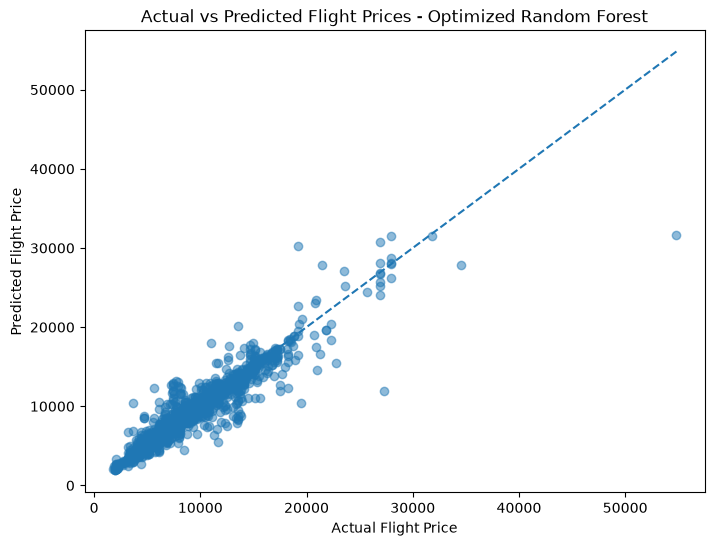

In [112]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test,best_rf_pred,alpha=0.5)

plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],linestyle="--")

plt.xlabel("Actual Flight Price")
plt.ylabel("Predicted Flight Price")
plt.title("Actual vs Predicted Flight Prices - Optimized Random Forest")

plt.show()

In [113]:
residuals = y_test.values - best_rf_pred

residual_df = pd.DataFrame({"Actual Price": y_test.values,"Predicted Price": best_rf_pred,"Residual": residuals})

residual_df.head(10)

,Actual Price,Predicted Price,Residual
0,17996,14999.13000,2996.87000
1,3873,3877.06000,-4.06000
2,4462,4292.06000,169.94000
3,2228,2282.35500,-54.35500
4,4991,4327.99000,663.01000
5,7229,7442.36500,-213.36500
6,14086,14224.01875,-138.01875
7,6386,6321.92000,64.08000
8,6628,6252.04000,375.96000
9,6934,6461.83000,472.17000


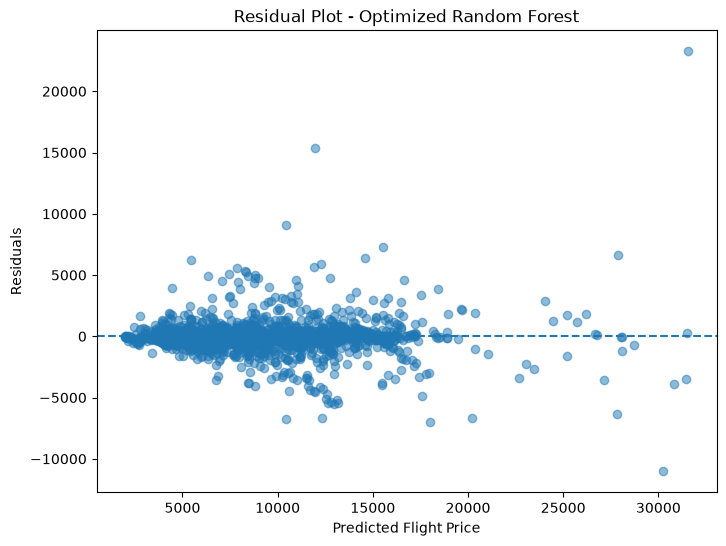

In [114]:
plt.figure(figsize=(8, 6))

plt.scatter(best_rf_pred,residuals,alpha=0.5)

plt.axhline(y=0,linestyle="--")

plt.xlabel("Predicted Flight Price")
plt.ylabel("Residuals")
plt.title("Residual Plot - Optimized Random Forest")

plt.show()

In [115]:
final_model_comparison = pd.DataFrame({"Model": ["Linear Regression","Decision Tree","Random Forest","Optimized Random Forest"],
                                       "MAE": [mae, dt_mae, rf_mae, best_rf_mae],"RMSE": [rmse, dt_rmse, rf_rmse, best_rf_rmse],
                                       "R2 Score": [r2, dt_r2, rf_r2, best_rf_r2]})

final_model_comparison.round(4)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1542.8683,2362.9786,0.7301
1,Decision Tree,976.8631,1917.8630,0.8222
2,Random Forest,634.2135,1339.2780,0.9133
3,Optimized Random Forest,615.6925,1324.5016,0.9152


In [116]:
feature_importance = pd.DataFrame({"Feature": encoded_feature_names,"Importance": best_rf_model.feature_importances_})

feature_importance = feature_importance.sort_values(by="Importance",ascending=False)

feature_importance.head(15)

,Feature,Importance
164,num__Duration_Minutes,0.432259
158,num__Journey_Day,0.100482
154,cat__Additional_Info_In-flight meal not included,0.076122
5,cat__Airline_Jet Airways Business,0.068914
4,cat__Airline_Jet Airways,0.056303
159,num__Journey_Month,0.046780
165,num__Total_Stops_Numeric,0.022867
6,cat__Airline_Multiple carriers,0.018659
160,num__Departure_Hour,0.017631
161,num__Departure_Minute,0.016618


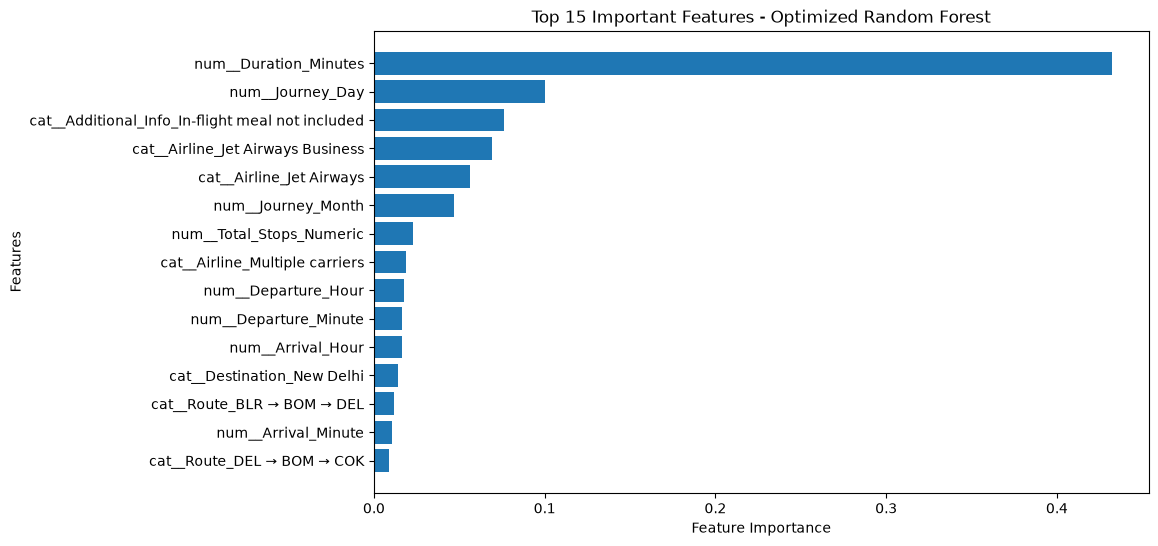

In [117]:
plt.figure(figsize=(10, 6))

top_features = feature_importance.head(15)

plt.barh(top_features["Feature"],top_features["Importance"])

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Important Features - Optimized Random Forest")

plt.gca().invert_yaxis()

plt.show()

# Conclusion

The notebook compares Linear Regression, Decision Tree, Random Forest, and an optimized Random Forest model for flight fare prediction. Based on the recorded test-set evaluation, the optimized Random Forest is the selected model.

The previously recorded optimized-model test metrics were **MAE = ₹615.69**, **RMSE = ₹1,324.50**, and **R² = 0.9152**. These metrics should be reconfirmed by running the notebook from a fresh kernel after the organization changes.

The model's performance is evaluated on this dataset and split; it should not be interpreted as a guarantee of accuracy for future fares or other datasets.

In [118]:
import pickle

flight_model_package = {
    "preprocessor": preprocessor,
    "model": best_rf_model,
    "categorical_features": categorical_features,
    "numerical_features": numerical_features
}

with open("flight_fare_model.pkl", "wb") as file:
    pickle.dump(flight_model_package, file)

print("Model package saved as flight_fare_model.pkl")

Model package saved as flight_fare_model.pkl


In [119]:
# Reload the saved package to verify that it can be opened
with open("flight_fare_model.pkl", "rb") as file:
    loaded_flight_package = pickle.load(file)

print("Loaded package keys:", list(loaded_flight_package.keys()))
print("Model expects features:", loaded_flight_package["model"].n_features_in_)
print("Preprocessor output features:", len(loaded_flight_package["preprocessor"].get_feature_names_out()))

Loaded package keys: ['preprocessor', 'model', 'categorical_features', 'numerical_features']
Model expects features: 166
Preprocessor output features: 166


In [120]:
import sys

print("Python Executable:")
print(sys.executable)


Python Executable:
c:\Users\Hp\Desktop\Visual St\.venv\Scripts\python.exe


In [121]:
import pickle
import os

# Check whether the file exists
print("File Exists:", os.path.exists("flight_fare_model.pkl"))

# Load the saved package
with open("flight_fare_model.pkl", "rb") as file:
    loaded_package = pickle.load(file)

# Check package components
print("\nLoaded Package Components:")
print(list(loaded_package.keys()))

File Exists: True


c:\Users\Hp\Desktop\Visual St\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator OneHotEncoder from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Hp\Desktop\Visual St\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Hp\Desktop\Visual St\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator ColumnTransformer from version 1.9.0 when using version


Loaded Package Components:
['preprocessor', 'model', 'categorical_features', 'numerical_features']


c:\Users\Hp\Desktop\Visual St\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RandomForestRegressor from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [122]:
import sklearn

print("Current Scikit-learn Version:", sklearn.__version__)

Current Scikit-learn Version: 1.9.1


In [123]:
import pickle
import sklearn

# Prepare the final model package
flight_model_package = {
    "preprocessor": preprocessor,
    "model": best_rf_model,
    "categorical_features": categorical_features,
    "numerical_features": numerical_features,
    "sklearn_version": sklearn.__version__
}

# Save the updated package
with open("flight_fare_model.pkl", "wb") as file:
    pickle.dump(flight_model_package, file)

print("Pickle file updated successfully!")
print("Scikit-learn Version:", sklearn.__version__)

Pickle file updated successfully!
Scikit-learn Version: 1.9.1


In [124]:
with open("flight_fare_model.pkl", "rb") as file:
    loaded_package = pickle.load(file)

print("Loaded Successfully!")
print("Saved Scikit-learn Version:",
      loaded_package["sklearn_version"])
print("Model:", loaded_package["model"])

Loaded Successfully!
Saved Scikit-learn Version: 1.9.1
Model: RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)


In [125]:
# Select one record from the test dataset
sample_input = X_test.iloc[[0]]

# Retrieve the saved preprocessor and model
loaded_preprocessor = loaded_package["preprocessor"]
loaded_model = loaded_package["model"]

# Transform the sample input
sample_processed = loaded_preprocessor.transform(sample_input)

# Predict flight fare
predicted_price = loaded_model.predict(sample_processed)

# Compare actual and predicted fare
actual_price = y_test.iloc[0]

print("Actual Flight Fare: ₹", actual_price)
print("Predicted Flight Fare: ₹", round(predicted_price[0], 2))
print("Absolute Error: ₹", round(abs(actual_price - predicted_price[0]), 2))


Actual Flight Fare: ₹ 17996
Predicted Flight Fare: ₹ 14999.13
Absolute Error: ₹ 2996.87
